# Fase 02 : Análisis descriptivo
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Septiembre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Descripción de los datos con los que se va a trabajar

* **Fase del Proyecto:** Segunda fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [1]:
from pathlib import Path

import polars as pl
import polars.selectors as cs
import seaborn as sns
from matplotlib import ticker
from pyprojroot import here


<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

Carga de datos limpios

In [2]:
df_01 = pl.read_parquet(source = Path(here(), '01_cleaned_data', 'df_01.parquet'))
df_01.glimpse()

Rows: 964947
Columns: 10
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000933', 'PRD_000201', 'PRD_000197', 'PRD_000177', 'PRD_001529', 'PRD_001525', 'PRD_000506', 'PRD_000951', 'PRD_00092

<h3 style="color:#05856d">3. Análisis descriptivo individual</h3>
<hr>

In [3]:
# Variables categóricas
df_02_cat = df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') )
df_02_cat.glimpse()

# Variables numéricas y de fecha
df_02_num = df_01.select(cs.numeric() | cs.by_name('ordered_on'))
df_02_num.glimpse()

Rows: 964947
Columns: 2
$ category_name <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc       <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI

Rows: 964947
Columns: 7
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ sales_bottles     <i64> 2, 6, 7, 2, 12, 8, 7, 2, 2, 2
$ sales_dollars     <f64> 34.5, 103.5, 34.16, 17.28, 225.0, 42.0, 68.25, 34.

Frecuencia de órdenes por categoría

In [4]:
df_02_cat.\
    get_column('category_name').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",150281,0.15574
"""CANADIAN WHISKIES""",94301,0.097727
"""STRAIGHT BOURBON WHISKIES""",79606,0.082498
"""WHISKEY LIQUEUR""",73023,0.075676
"""100% AGAVE TEQUILA""",56097,0.058135
…,…,…
"""NEUTRAL GRAIN SPIRITS""",1426,0.001478
"""MEZCAL""",1117,0.001158
"""SPECIAL ORDER ITEMS""",331,0.000343


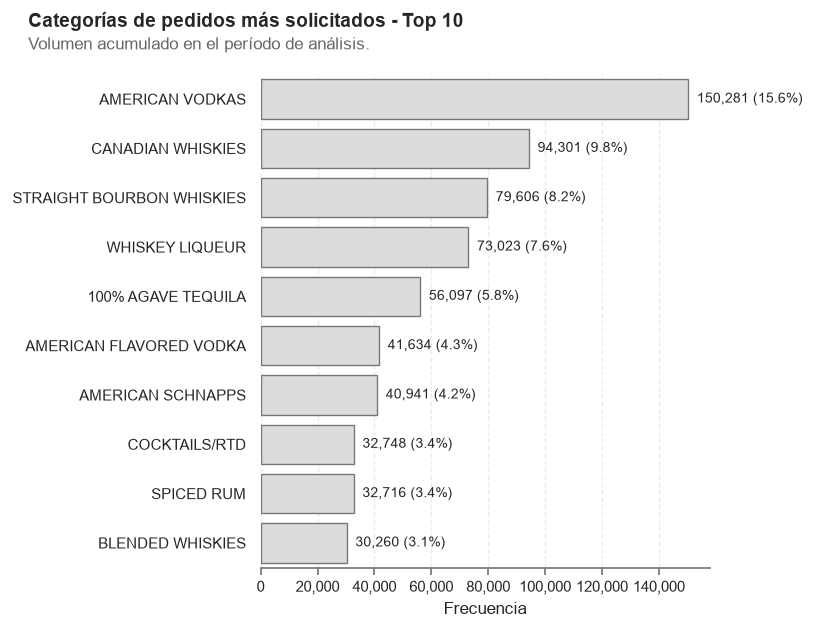

In [7]:
# 1. Preparación de datos
analysis_category_name = (
    df_02_cat
    .get_column('category_name')
    .value_counts(name = 'count_0', sort = True)
    .with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )
    .head(10)
)

# 2. Tema general con Seaborn
sns.set_theme( context = 'paper', style = 'white',
rc = {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.4})

# 3. Gráfico de barras
g = sns.catplot(
    data = analysis_category_name,
    x = 'count_0',
    y = 'category_name',
    kind = 'bar',
    color = '#DCDCDC',
    edgecolor = '#777777',
    height = 5, # Altura en pulgadas
    aspect = 1.2, # Ancho = 5 * 1.2 = 6 pulgadas
)

# 4. Ajustes directos en el objeto FacetGrid de Seaborn
g.despine(left = True, bottom = False)
g.set_axis_labels( x_var = 'Frecuencia', y_var = '' )
g.figure.subplots_adjust(top = 0.90)

g.figure.suptitle(
    'Categorías de pedidos más solicitados - Top 10',
    x = 0.08,
    y = 1.00,
    ha = 'left',
    weight = 'bold',
    size = 11
)

g.figure.text(
    x = 0.08,
    y = 0.94,
    s = 'Volumen acumulado en el período de análisis.',
    ha = 'left',
    fontsize = 10,
    color = '#666666'
)

# 5. Formato al eje X y etiquetas de barras

etiquetas_barras = [
    f"{cnt:,.0f} ({pct:.1%})"
    for cnt, pct in zip(analysis_category_name['count_0'], analysis_category_name['ptc_0'])
]

for ax in g.axes.flat:
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.tick_params(axis = 'x', bottom = True, length = 4, color = '#777777')
    ax.spines['bottom'].set_color('#777777')
    ax.bar_label(ax.containers[0], labels = etiquetas_barras, padding = 5, fontsize = 8)

# Exportar gráfico
g.figure.savefig(
    Path(here(),'05_graphs','01_top_10_categorias.png'),
    dpi = 300,
    bbox_inches = 'tight',
    facecolor = 'white'
)

Clasificar los tipos de 